In [1]:
!pip install ultralytics opencv-python matplotlib pyyaml kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 20.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [2]:
from ultralytics import YOLO
import os
import yaml
import cv2
import matplotlib.pyplot as plt
import glob
import kagglehub
from sklearn.model_selection import train_test_split

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
path = kagglehub.dataset_download("fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset")
print("Path to dataset files:", path)
dataset = os.path.join(path, "Visual Pollution Dataset")

Path to dataset files: /kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset


In [4]:
for root, dirs, files in os.walk(dataset):
    print(root, len(files))

/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset 1
/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/images 0
/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/images/train 24553
/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/images/val 7242
/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/labels 0
/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/labels/train 24553
/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/labels/val 7242


In [5]:
yaml_files = glob.glob(path + "/**/*.yaml", recursive=True)

yaml_files

['/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/dataset.yaml']

In [6]:
with open(yaml_files[0], "r") as f:
    data_yaml = yaml.safe_load(f)

data_yaml

{'train': '../datasets/al_round_004/images/train',
 'val': '../datasets/al_round_004/images/val',
 'nc': 3,
 'names': ['barriers', 'sidewalks', 'pothole']}

used kaggle notebook since the dataset is large to download and train on google colab

In [7]:
for root, dirs, files in os.walk(path):
    print(root, len(files))

/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset 0
/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset 1
/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/images 0
/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/images/train 24553
/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/images/val 7242
/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/labels 0
/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/labels/train 24553
/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/labels/val 7242


In [8]:
path

'/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset'

splitting the validation so that we have somthing to test the values

In [9]:
images=sorted(glob.glob(path+"/Visual Pollution Dataset/images/val/*"))
val, test = train_test_split(
    sorted(images),
    test_size=0.5,
    random_state=42
)

print("Validation:", len(val))
print("Testing:", len(test))

Validation: 3621
Testing: 3621


In [10]:
print("Overlap:", len(set(val) & set(test)))

Overlap: 0


In [11]:
with open("/kaggle/working/val.txt", "w") as f:
    f.write("\n".join(val))

with open("/kaggle/working/test.txt", "w") as f:
    f.write("\n".join(test))

creating a list of the images within the test since it only contained the paths of the images

In [12]:
with open("/kaggle/working/test.txt", "r") as f:
    test_img = f.read().splitlines()

creating our new yaml

In [13]:
data_yaml = {
    "train": os.path.join(dataset, "images", "train"),
    "val": "/kaggle/working/val.txt",
    "test": "/kaggle/working/test.txt",
    "nc": 3,
    "names": ["barriers", "sidewalks", "pothole"]
}

In [14]:
yaml_path = "/kaggle/working/data.yaml"
with open(yaml_path, "w") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)

In [15]:
with open(yaml_path, "r") as f:
    data_yaml = yaml.safe_load(f)

data_yaml

{'train': '/kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/images/train',
 'val': '/kaggle/working/val.txt',
 'test': '/kaggle/working/test.txt',
 'nc': 3,
 'names': ['barriers', 'sidewalks', 'pothole']}

In [16]:
model = YOLO("yolov8n.pt")

Ultralytics has early stopping built in through patience
making patience=5 will allow YOLO to add 5 epochs to beat its best validation score if after 5 epochs score didnt improve training stops
though keep in mind we made it 5 because it less time to execute though we can do 10 for a better improvement

In [17]:
res = model.train(data=yaml_path, epochs=30, imgsz=640, batch=100,patience=5)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=100, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      11.3G      1.518      1.895      1.434        125        640: 100% ━━━━━━━━━━━━ 246/246 1.4it/s 2:500.5ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 1.1s/it 20.9s1.0ss
                   all       3621       4794      0.358      0.382      0.327      0.176

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      11.3G      1.522      1.876       1.45        132        640: 100% ━━━━━━━━━━━━ 246/246 1.5it/s 2:470.5ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 1.1s/it 21.7s1.0ss
                   all       3621       4794      0.264      0.313       0.23      0.112

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      11.3G        1.5      1.806      1.433        124        640: 100% ━━━━━━━━━━━━ 246/246 1.5it/s 2:450.5ss
                 Class     Im

In [18]:
val = model.val()

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 209.5±51.5 MB/s, size: 109.1 KB)
val: Scanning /kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/labels/val... 3621 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3621/3621 792.3it/s 4.6s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 227/227 8.0it/s 28.3s0.1ss
                   all       3621       4794      0.632      0.644      0.681      0.446
              barriers        732        924      0.619      0.627      0.663      0.474
             sidewalks       

In [19]:
print(val)

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7afe74adc2f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [20]:
print(f"Precision: {val.box.mp:.2%}")
print(f"Recall: {val.box.mr:.2%}")
print(f"mAP50: {val.box.map50:.2%}")
print(f"mAP50-95: {val.box.map:.2%}")

Precision: 63.24%
Recall: 64.37%
mAP50: 68.08%
mAP50-95: 44.56%


In [21]:
test = test_img[0]
res2 = model.predict(test)


image 1/1 /kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/images/val/DATA-WORKATTACH-FILE MOMRA-OPS-CS-WORK INC-21-08-021021!20210807T161906.177 GMT.jpg: 640x480 1 pothole, 11.7ms
Speed: 43.5ms preprocess, 11.7ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 480)


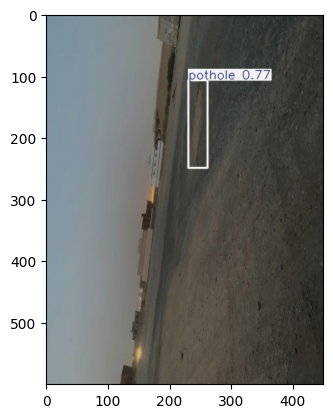

In [22]:
plt.imshow(cv2.cvtColor(res2[0].plot(), cv2.COLOR_BGR2RGB))

In [23]:
test_results = model.val(data=yaml_path, split="test")
print("Test results")
print(f"Precision: {test_results.box.mp:.2%}")
print(f"Recall: {test_results.box.mr:.2%}")
print(f"mAP50: {test_results.box.map50:.2%}")
print(f"mAP50-95: {test_results.box.map:.2%}")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.1 ms, read: 1.3±0.4 MB/s, size: 92.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/labels/val... 3621 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 3621/3621 15.2it/s 3:580.1ss
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 227/227 1.9it/s 1:590.2sss
                   all       3621       4808        0.6 

In [24]:
test = test_img[1]
res2 = model.predict(test)


image 1/1 /kaggle/input/datasets/fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset/Visual Pollution Dataset/images/val/DATA-WORKATTACH-FILE MOMRA-OPS-CS-WORK INC-21-09-029314!20210904T135043.521 GMT.jpg: 640x480 2 sidewalkss, 12.4ms
Speed: 1.9ms preprocess, 12.4ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 480)


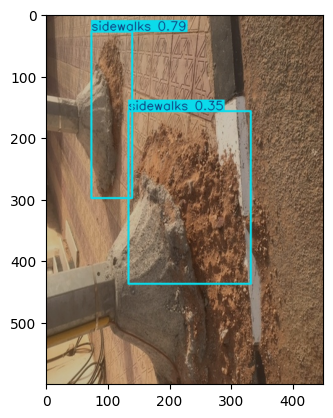

In [25]:
plt.imshow(cv2.cvtColor(res2[0].plot(), cv2.COLOR_BGR2RGB))

exporting model

In [26]:
model.export(format="onnx")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/kaggle/working/runs/detect/train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (6.2 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 557ms
Prepared 2 packages in 434ms
Installed 2 packages in 10ms
 + onnxruntime==1.32.0
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 3.0s, save

'/kaggle/working/runs/detect/train/weights/best.onnx'